# Computación Avanzada y Analítica
# Diferencias finitas: implementaciones y experimentos numéricos

In [1]:
import numpy as np
import matplotlib.pyplot as plt

# 1. DIFERENCIAS FINITAS PARA LA PRIMERA DERIVADA

In [2]:
def diferencia_adelante(f, x, h):
    # Aproximación mediante diferencia hacia adelante.
    return (f(x + h) - f(x)) / h


def diferencia_atras(f, x, h):
    # Aproximación mediante diferencia hacia atrás.
    return (f(x) - f(x - h)) / h


def diferencia_centrada(f, x, h):
    # Aproximación mediante diferencia centrada.
    return (f(x + h) - f(x - h)) / (2 * h)

# 2. SEGUNDA DERIVADA

In [3]:
def segunda_derivada_centrada(f, x, h):
    # Aproximación de la segunda derivada centrada.
    return (f(x + h) - 2 * f(x) + f(x - h)) / h**2

# 3. ERRORES

In [4]:
def error_absoluto(valor_aproximado, valor_exacto):
    return abs(valor_aproximado - valor_exacto)


def error_relativo(valor_aproximado, valor_exacto):
    if valor_exacto == 0:
        return np.nan
    return abs(valor_aproximado - valor_exacto) / abs(valor_exacto)


def error_porcentual(valor_aproximado, valor_exacto):
    return 100 * error_relativo(valor_aproximado, valor_exacto)

# 4. EJEMPLO BÁSICO: f(x) = x^2

In [5]:
f = lambda x: x**2
derivada_exacta = lambda x: 2*x

x = 2.0
h = 0.1

exacta = derivada_exacta(x)
adelante = diferencia_adelante(f, x, h)
atras = diferencia_atras(f, x, h)
centrada = diferencia_centrada(f, x, h)

print("=" * 60)
print("EJEMPLO: f(x) = x^2")
print("=" * 60)
print(f"Derivada exacta en x={x}: {exacta}")
print(f"Diferencia hacia adelante: {adelante}")
print(f"Diferencia hacia atrás:    {atras}")
print(f"Diferencia centrada:       {centrada}")

print("\nErrores absolutos:")
print(f"Adelante: {error_absoluto(adelante, exacta)}")
print(f"Atrás:    {error_absoluto(atras, exacta)}")
print(f"Centrada: {error_absoluto(centrada, exacta)}")

EJEMPLO: f(x) = x^2
Derivada exacta en x=2.0: 4.0
Diferencia hacia adelante: 4.100000000000001
Diferencia hacia atrás:    3.9000000000000012
Diferencia centrada:       4.000000000000001

Errores absolutos:
Adelante: 0.10000000000000142
Atrás:    0.09999999999999876
Centrada: 8.881784197001252e-16


# 5. COMPARACIÓN CON f(x) = sin(x)

In [6]:
f = np.sin
derivada_exacta = np.cos
x = 1.0
valores_h = [1e-1, 1e-2, 1e-3, 1e-4]

print("\n" + "=" * 60)
print("COMPARACIÓN: f(x) = sin(x)")
print("=" * 60)

exacta = derivada_exacta(x)
print(f"Valor exacto: {exacta:.12f}\n")

print(
    f"{'h':>10} "
    f"{'Error adelante':>20} "
    f"{'Error atrás':>20} "
    f"{'Error centrada':>20}"
)

for h in valores_h:
    a = diferencia_adelante(f, x, h)
    b = diferencia_atras(f, x, h)
    c = diferencia_centrada(f, x, h)

    ea = error_absoluto(a, exacta)
    eb = error_absoluto(b, exacta)
    ec = error_absoluto(c, exacta)

    print(f"{h:10.1e} {ea:20.12e} {eb:20.12e} {ec:20.12e}")



COMPARACIÓN: f(x) = sin(x)
Valor exacto: 0.540302305868

         h       Error adelante          Error atrás       Error centrada
   1.0e-01   4.293855333275e-02   4.113844593599e-02   9.000536983798e-04
   1.0e-02   4.216324856271e-03   4.198314869458e-03   9.004993406281e-06
   1.0e-03   4.208255078129e-04   4.206454069124e-04   9.005045020771e-08
   1.0e-04   4.207444951865e-05   4.207264865963e-05   9.004295087323e-10


# 6. ESTIMACIÓN EXPERIMENTAL DEL ORDEN

In [7]:
def orden_convergencia(error1, error2, h1, h2):
    # Estima p suponiendo E ≈ C*h^p.
    return np.log(error1 / error2) / np.log(h1 / h2)


errores_adelante = []
errores_atras = []
errores_centrada = []

for h in valores_h:
    a = diferencia_adelante(f, x, h)
    b = diferencia_atras(f, x, h)
    c = diferencia_centrada(f, x, h)

    errores_adelante.append(error_absoluto(a, exacta))
    errores_atras.append(error_absoluto(b, exacta))
    errores_centrada.append(error_absoluto(c, exacta))

print("\n" + "=" * 60)
print("ORDEN EXPERIMENTAL DE CONVERGENCIA")
print("=" * 60)

for i in range(len(valores_h) - 1):
    h1 = valores_h[i]
    h2 = valores_h[i + 1]

    p_a = orden_convergencia(
        errores_adelante[i], errores_adelante[i + 1], h1, h2
    )
    p_b = orden_convergencia(
        errores_atras[i], errores_atras[i + 1], h1, h2
    )
    p_c = orden_convergencia(
        errores_centrada[i], errores_centrada[i + 1], h1, h2
    )

    print(f"h: {h1:.0e} -> {h2:.0e}")
    print(f"  Adelante: {p_a:.4f}")
    print(f"  Atrás:    {p_b:.4f}")
    print(f"  Centrada: {p_c:.4f}")



ORDEN EXPERIMENTAL DE CONVERGENCIA
h: 1e-01 -> 1e-02
  Adelante: 1.0079
  Atrás:    0.9912
  Centrada: 1.9998
h: 1e-02 -> 1e-03
  Adelante: 1.0008
  Atrás:    0.9992
  Centrada: 2.0000
h: 1e-03 -> 1e-04
  Adelante: 1.0001
  Atrás:    0.9999
  Centrada: 2.0000


# 7. GRÁFICA DEL ERROR

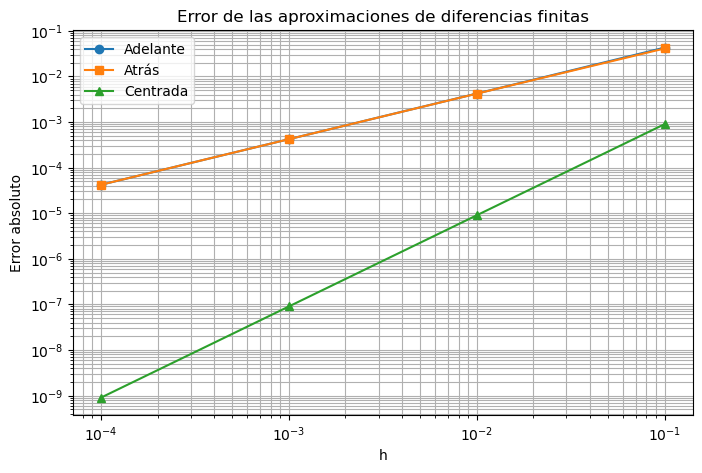

In [8]:
plt.figure(figsize=(8, 5))
plt.loglog(valores_h, errores_adelante, marker="o", label="Adelante")
plt.loglog(valores_h, errores_atras, marker="s", label="Atrás")
plt.loglog(valores_h, errores_centrada, marker="^", label="Centrada")
plt.xlabel("h")
plt.ylabel("Error absoluto")
plt.title("Error de las aproximaciones de diferencias finitas")
plt.grid(True, which="both")
plt.legend()
plt.show()

# 8. APLICACIÓN FÍSICA: VELOCIDAD

In [9]:
t = np.array([0, 1, 2, 3, 4], dtype=float)
x_pos = np.array([0, 3, 8, 15, 24], dtype=float)
dt = t[1] - t[0]

print("\n" + "=" * 60)
print("APLICACIÓN FÍSICA: VELOCIDAD")
print("=" * 60)

vel_adelante = np.diff(x_pos) / dt
vel_atras = np.diff(x_pos) / dt
vel_centrada = (x_pos[2:] - x_pos[:-2]) / (2 * dt)

print("Velocidades hacia adelante:")
print(vel_adelante)

print("\nVelocidades hacia atrás:")
print(vel_atras)

print("\nVelocidades centradas en puntos interiores:")
print(vel_centrada)


APLICACIÓN FÍSICA: VELOCIDAD
Velocidades hacia adelante:
[3. 5. 7. 9.]

Velocidades hacia atrás:
[3. 5. 7. 9.]

Velocidades centradas en puntos interiores:
[4. 6. 8.]


# 9. APLICACIÓN FÍSICA: ACELERACIÓN

In [10]:
aceleracion = (
    x_pos[2:] - 2 * x_pos[1:-1] + x_pos[:-2]
) / dt**2

print("\n" + "=" * 60)
print("APLICACIÓN FÍSICA: ACELERACIÓN")
print("=" * 60)
print("Aceleración en puntos interiores:")
print(aceleracion)


APLICACIÓN FÍSICA: ACELERACIÓN
Aceleración en puntos interiores:
[2. 2. 2.]


# 10. FUNCIONES PARA DATOS DISCRETOS

In [11]:
def derivada_adelante_datos(y, h):
    # Primera derivada hacia adelante para datos igualmente espaciados.
    return np.diff(y) / h


def derivada_atras_datos(y, h):
    # Primera derivada hacia atrás para datos igualmente espaciados.
    return np.diff(y) / h


def derivada_centrada_datos(y, h):
    # Primera derivada centrada en puntos interiores.
    return (y[2:] - y[:-2]) / (2 * h)


def segunda_derivada_centrada_datos(y, h):
    # Segunda derivada centrada en puntos interiores.
    return (y[2:] - 2 * y[1:-1] + y[:-2]) / h**2


# 11. EJERCICIO: DATOS DE POSICIÓN

In [12]:
t = np.array([0, 1, 2, 3, 4, 5], dtype=float)
x_pos = np.array([0, 2, 7, 15, 26, 40], dtype=float)
h = 1.0

v_adelante = derivada_adelante_datos(x_pos, h)
v_atras = derivada_atras_datos(x_pos, h)
v_centrada = derivada_centrada_datos(x_pos, h)
a_centrada = segunda_derivada_centrada_datos(x_pos, h)

print("\n" + "=" * 60)
print("EJERCICIO: POSICIÓN, VELOCIDAD Y ACELERACIÓN")
print("=" * 60)
print("Tiempo:")
print(t)
print("\nPosición:")
print(x_pos)
print("\nVelocidad hacia adelante:")
print(v_adelante)
print("\nVelocidad hacia atrás:")
print(v_atras)
print("\nVelocidad centrada:")
print(v_centrada)
print("\nAceleración centrada:")
print(a_centrada)


EJERCICIO: POSICIÓN, VELOCIDAD Y ACELERACIÓN
Tiempo:
[0. 1. 2. 3. 4. 5.]

Posición:
[ 0.  2.  7. 15. 26. 40.]

Velocidad hacia adelante:
[ 2.  5.  8. 11. 14.]

Velocidad hacia atrás:
[ 2.  5.  8. 11. 14.]

Velocidad centrada:
[ 3.5  6.5  9.5 12.5]

Aceleración centrada:
[3. 3. 3. 3.]


# 12. FUNCIÓN GENERAL DE COMPARACIÓN

In [13]:
def comparar_metodos(f, derivada, x, valores_h):
    # Compara aproximaciones y errores para varios valores de h.
    resultados = []
    exacta = derivada(x)

    for h in valores_h:
        a = diferencia_adelante(f, x, h)
        b = diferencia_atras(f, x, h)
        c = diferencia_centrada(f, x, h)

        resultados.append({
            "h": h,
            "exacta": exacta,
            "adelante": a,
            "atras": b,
            "centrada": c,
            "error_adelante": error_absoluto(a, exacta),
            "error_atras": error_absoluto(b, exacta),
            "error_centrada": error_absoluto(c, exacta),
        })

    return resultados


resultados = comparar_metodos(
    np.sin,
    np.cos,
    1.0,
    [1e-1, 1e-2, 1e-3, 1e-4, 1e-5, 1e-6]
)

print("\n" + "=" * 60)
print("TABLA DE COMPARACIÓN")
print("=" * 60)

for resultado in resultados:
    print(
        f"h={resultado['h']:.1e} | "
        f"E adelante={resultado['error_adelante']:.3e} | "
        f"E atrás={resultado['error_atras']:.3e} | "
        f"E centrada={resultado['error_centrada']:.3e}"
    )



TABLA DE COMPARACIÓN
h=1.0e-01 | E adelante=4.294e-02 | E atrás=4.114e-02 | E centrada=9.001e-04
h=1.0e-02 | E adelante=4.216e-03 | E atrás=4.198e-03 | E centrada=9.005e-06
h=1.0e-03 | E adelante=4.208e-04 | E atrás=4.206e-04 | E centrada=9.005e-08
h=1.0e-04 | E adelante=4.207e-05 | E atrás=4.207e-05 | E centrada=9.004e-10
h=1.0e-05 | E adelante=4.207e-06 | E atrás=4.207e-06 | E centrada=1.114e-11
h=1.0e-06 | E adelante=4.207e-07 | E atrás=4.208e-07 | E centrada=2.772e-11


# 13. OBSERVACIÓN DEL ERROR DE REDONDEO

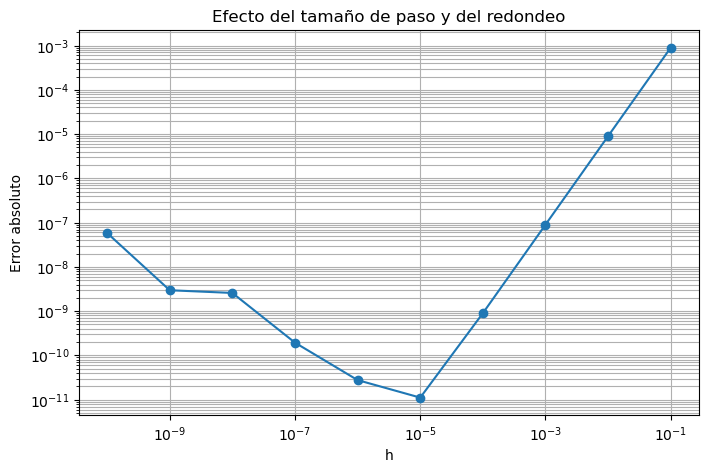

In [14]:
valores_h_pequenos = [
    1e-1, 1e-2, 1e-3, 1e-4, 1e-5,
    1e-6, 1e-7, 1e-8, 1e-9, 1e-10
]

errores = []

for h in valores_h_pequenos:
    aproximacion = diferencia_centrada(np.sin, 1.0, h)
    errores.append(error_absoluto(aproximacion, np.cos(1.0)))

plt.figure(figsize=(8, 5))
plt.loglog(valores_h_pequenos, errores, marker="o")
plt.xlabel("h")
plt.ylabel("Error absoluto")
plt.title("Efecto del tamaño de paso y del redondeo")
plt.grid(True, which="both")
plt.show()


# 14. ACTIVIDAD PROPUESTA


1. Utilice f(x) = exp(x) y calcule f'(1).
2. Compare las tres diferencias para h = 10^-1, ..., 10^-4.
3. Calcule el error absoluto.
4. Estime experimentalmente el orden de convergencia.
5. Explique por qué la diferencia centrada es más precisa.
6. Para t=[0,1,2,3,4,5] y x=[0,2,7,15,26,40], calcule velocidad y aceleración.
7. Explique qué ocurre en los extremos al usar diferencia centrada.
